<a href="https://colab.research.google.com/github/tishasetia13/planet-or-not/blob/main/planet_or_not_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Planet or Not
Classifies Kepler objects of interest as confirmed planets or false positives, using NASA's KOI table.

**To run:**
1. On the NASA Exoplanet Archive, open the Cumulative KOI table, click Download Table, and choose CSV with all columns.
2. Upload the file to Colab's Files panel and name it `koi_cumulative.csv`.
3. Runtime → Run all.

In [25]:
# ===== 1. LOAD THE DATA AND CHECK IT =====

# Stage 1: settings
import numpy as np
import pandas as pd

CSV_PATH = "koi_cumulative.csv"    # the NASA table, uploaded to Colab's Files panel
SEED = 42                          # fixed random seed, so the star split is the same every run

# Stage 2: load the table
def load_koi_table(path):
    """Read the KOI CSV, skipping the archive's '#' comment lines at the top."""
    return pd.read_csv(path, comment="#")

koi = load_koi_table(CSV_PATH)
print("Rows and columns:", koi.shape)               # expect (9564, 141)
print(koi["koi_disposition"].value_counts())        # expect FALSE POSITIVE 4839, CONFIRMED 2748, CANDIDATE 1977

# Stage 3: which columns have the most missing values?
def missing_report(df):
    """Return a table of missing counts and percentages per column, emptiest first."""
    counts = df.isna().sum()
    percent = (counts / len(df) * 100).round(1)
    report = pd.DataFrame({"missing": counts, "percent": percent})
    return report.sort_values("missing", ascending=False)

print(missing_report(koi).head(25))

# Stage 4: check that the main columns we plan to use exist
wanted = ["kepid", "kepoi_name", "koi_disposition", "koi_period",
          "koi_time0bk", "koi_depth", "koi_prad", "koi_model_snr"]
print("Missing from the table:", [c for c in wanted if c not in koi.columns])    # expect []

Rows and columns: (9564, 141)
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64
                  missing  percent
koi_incl_err1        9564    100.0
koi_sma_err2         9564    100.0
koi_sma_err1         9564    100.0
koi_teq_err1         9564    100.0
koi_teq_err2         9564    100.0
koi_longp_err2       9564    100.0
koi_ingress          9564    100.0
koi_ingress_err2     9564    100.0
koi_ingress_err1     9564    100.0
koi_longp_err1       9564    100.0
koi_longp            9564    100.0
koi_eccen_err2       9564    100.0
koi_eccen_err1       9564    100.0
koi_sage_err1        9564    100.0
koi_sage_err2        9564    100.0
koi_sage             9564    100.0
koi_model_dof        9564    100.0
koi_model_chisq      9564    100.0
koi_incl_err2        9564    100.0
kepler_name          6816     71.3
koi_bin_oedp_sig     1510     15.8
koi_score            1510     15.8
koi_comment          1209     12.6
koi_max_sngle_ev   

In [26]:
# ===== 2. LEAKAGE CHECK (on the full table, on purpose) =====
# Leakage = columns that reveal the answer. We measure which columns do, BEFORE dropping them.

# Stage 1: keep only the rows that have a final answer
def labeled_only(df):
    """Return a copy of the table containing only CONFIRMED and FALSE POSITIVE rows."""
    keep = df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])
    return df[keep].copy()

# Stage 2: compare the suspect columns with the label
def leak_report(df):
    """Print three tables showing how the suspect columns line up with the label."""
    label = df["koi_disposition"]

    print("1) Is kepler_name filled?")
    print(pd.crosstab(label, df["kepler_name"].notna()), "\n")

    print("2) koi_pdisposition (the Kepler pipeline's own verdict)")
    print(pd.crosstab(label, df["koi_pdisposition"]), "\n")

    # the mean of a 0/1 column is the share of rows with a 1
    print("3) Average koi_score and share of rows flagged, per label")
    suspects = ["koi_score", "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
    print(df.groupby("koi_disposition")[suspects].mean().round(3))

leak_report(labeled_only(koi))

1) Is kepler_name filled?
kepler_name      False  True 
koi_disposition              
CONFIRMED            2   2746
FALSE POSITIVE    4837      2 

2) koi_pdisposition (the Kepler pipeline's own verdict)
koi_pdisposition  CANDIDATE  FALSE POSITIVE
koi_disposition                            
CONFIRMED              2739               9
FALSE POSITIVE            1            4838 

3) Average koi_score and share of rows flagged, per label
                 koi_score  koi_fpflag_nt  koi_fpflag_ss  koi_fpflag_co  \
koi_disposition                                                           
CONFIRMED            0.960          0.170          0.005           0.00   
FALSE POSITIVE       0.038          0.315          0.457           0.39   

                 koi_fpflag_ec  
koi_disposition                 
CONFIRMED                0.000  
FALSE POSITIVE           0.237  


In [27]:
# ===== 3. CHOOSE THE COLUMNS THE MODEL MAY USE =====

# Stage 1: a helper that drops columns and reports what happened
def drop_columns(df, cols, why):
    """Drop the given columns, print how many went and the new shape, return the smaller table."""
    smaller = df.drop(columns=cols)
    print(f"{why}: dropped {len(cols)} -> table is now {smaller.shape}")
    return smaller

# Stage 2: answer-key columns (they reveal or record the label)
answer_key_cols = [
    "kepler_name", "koi_pdisposition", "koi_score",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
    "koi_comment", "koi_vet_stat", "koi_vet_date",
    "koi_datalink_dvr", "koi_datalink_dvs",
]
koi_small = drop_columns(koi, answer_key_cols, "answer-key columns")       # expect 12 -> 129 columns

# Stage 3: columns where every cell is empty
empty_cols = [c for c in koi_small.columns if koi_small[c].isna().all()]
koi_small = drop_columns(koi_small, empty_cols, "empty columns")           # expect 19 -> 110 columns

# Stage 4: "give or take" (uncertainty) columns, found by how their names end
err_cols = [c for c in koi_small.columns if c.endswith(("_err", "_err1", "_err2"))]
koi_small = drop_columns(koi_small, err_cols, "uncertainty columns")       # expect 44 -> 66 columns

# Stage 5: "paperwork" columns (notes about how NASA's computers processed each row)
paperwork_cols = [
    "koi_disp_prov", "koi_parm_prov", "koi_tce_delivname", "koi_tce_plnt_num",
    "koi_fittype", "koi_limbdark_mod", "koi_trans_mod", "koi_sparprov",
    "koi_quarters", "koi_bin_oedp_sig", "koi_count",
]
koi_small = drop_columns(koi_small, paperwork_cols, "paperwork columns")   # expect 11 -> 55 columns

# Stage 6: "picture" columns (from telescope images, not the light curve), found by how their names begin
pixel_cols = [c for c in koi_small.columns
              if c.startswith(("koi_fwm_", "koi_dicco_", "koi_dikco_"))]
koi_small = drop_columns(koi_small, pixel_cols, "picture columns")         # expect 13 -> 42 columns

# Stage 7: give each remaining column a job
id_cols   = ["rowid", "kepid", "kepoi_name"]    # say which object each row is (never model inputs)
label_col = "koi_disposition"                   # the answer we want to predict
fold_cols = ["koi_time0bk", "koi_time0"]        # kept in case light curves are added later (not inputs)
special = id_cols + [label_col] + fold_cols
feature_cols = [c for c in koi_small.columns if c not in special]
print("Input columns:", len(feature_cols))      # expect 36

# Stage 8: safety check, no answer-key column may remain
assert not set(answer_key_cols) & set(koi_small.columns), "An answer-key column slipped through!"
print("Leak check passed")

answer-key columns: dropped 12 -> table is now (9564, 129)
empty columns: dropped 19 -> table is now (9564, 110)
uncertainty columns: dropped 44 -> table is now (9564, 66)
paperwork columns: dropped 11 -> table is now (9564, 55)
picture columns: dropped 13 -> table is now (9564, 42)
Input columns: 36
Leak check passed


In [28]:
# ===== 4. CHOOSE THE ROWS =====
# CANDIDATE rows have no confirmed answer, so we keep only CONFIRMED and FALSE POSITIVE rows.

clean = labeled_only(koi_small)
print("Clean table:", clean.shape)                                           # expect (7587, 42)
print(clean[label_col].value_counts())                                       # expect FALSE POSITIVE 4839, CONFIRMED 2748
print("Share confirmed:", round((clean[label_col] == "CONFIRMED").mean(), 3))   # expect 0.362

Clean table: (7587, 42)
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
Name: count, dtype: int64
Share confirmed: 0.362


In [29]:
# ===== 5. SPLIT BY STAR INTO TRAIN / VALIDATION / TEST =====
# One star can have several rows, so we deal out STARS (not rows). A star never lands in two piles.

# Stage 1: the dealing function
def assign_star_splits(star_ids, seed):
    """Shuffle the stars and deal them into train (70%), validation (15%) and test (15%)."""
    rng = np.random.default_rng(seed)            # random number generator, started from the seed
    shuffled = rng.permutation(star_ids)         # the same stars, in a random order
    n = len(shuffled)
    train_end = int(0.70 * n)                    # cut point after the first 70%
    val_end = int(0.85 * n)                      # cut point after the next 15%
    return {
        "train": shuffled[:train_end],
        "val":   shuffled[train_end:val_end],
        "test":  shuffled[val_end:],
    }

# Stage 2: deal the stars, then give every row the pile of its star
star_ids = clean["kepid"].unique()
star_splits = assign_star_splits(star_ids, SEED)
clean["split"] = "train"
clean.loc[clean["kepid"].isin(star_splits["val"]), "split"] = "val"
clean.loc[clean["kepid"].isin(star_splits["test"]), "split"] = "test"
print("Stars per pile:", {name: len(stars) for name, stars in star_splits.items()})   # expect 4648 / 996 / 997
print(clean["split"].value_counts())                                                  # expect train 5305, test 1150, val 1132

# Stage 3: check the split
def count_piles_per_star(df):
    """Return, for each star, how many different piles its rows are in."""
    return df.groupby("kepid")["split"].nunique()

print("Stars in more than one pile:", (count_piles_per_star(clean) > 1).sum())       # expect 0
print("Stars dealt:", sum(len(s) for s in star_splits.values()),
      " Stars in table:", len(star_ids))                                              # expect 6641 and 6641
planet_share = (clean[label_col] == "CONFIRMED").groupby(clean["split"]).mean()
print((planet_share * 100).round(1))                                                  # expect test 37.9, train 35.8, val 36.3
print(pd.crosstab(clean["split"], clean[label_col]))

# Stage 4: one table per pile (the test pile is made but NOT looked at)
train_df = clean[clean["split"] == "train"].copy()
val_df   = clean[clean["split"] == "val"].copy()
test_df  = clean[clean["split"] == "test"].copy()
print(len(train_df), len(val_df), len(test_df))                                       # expect 5305 1132 1150

Stars per pile: {'train': 4648, 'val': 996, 'test': 997}
split
train    5305
test     1150
val      1132
Name: count, dtype: int64
Stars in more than one pile: 0
Stars dealt: 6641  Stars in table: 6641
split
test     37.9
train    35.8
val      36.3
Name: koi_disposition, dtype: float64
koi_disposition  CONFIRMED  FALSE POSITIVE
split                                     
test                   436             714
train                 1901            3404
val                    411             721
5305 1132 1150


,rowid,kepid,kepoi_name,koi_disposition,koi_period,koi_eccen,koi_impact,koi_duration,koi_depth,koi_ror,koi_srho,koi_prad
3,4,10848459,K00754.01,FALSE POSITIVE,1.736952,0.0,1.276,2.40641,8079.2,0.387394,0.22080,33.46
5,6,10872983,K00756.01,CONFIRMED,11.094321,0.0,0.538,4.59450,1517.5,0.036779,0.67324,3.90
6,7,10872983,K00756.02,CONFIRMED,4.134435,0.0,0.762,3.14020,686.0,0.026133,0.37377,2.77
7,8,10872983,K00756.03,CONFIRMED,2.566589,0.0,0.755,2.42900,226.5,0.014983,0.48909,1.59
8,9,6721123,K00114.01,FALSE POSITIVE,7.361790,0.0,1.169,5.02200,233.7,0.183387,0.00485,39.21
12,13,6922244,K00010.01,CONFIRMED,3.522498,0.0,0.631,3.19843,9145.7,0.092086,0.65374,14.59
13,14,10984090,K00112.02,CONFIRMED,3.709214,0.0,0.051,2.63020,131.1,0.010424,1.77451,1.16
15,16,10464078,K00743.01,FALSE POSITIVE,19.403938,0.0,0.804,12.21550,8918.7,0.096729,0.03785,7.18
16,17,10480982,K00744.01,FALSE POSITIVE,19.221389,0.0,1.065,4.79843,74284.0,0.476633,1.57359,49.29
17,18,10485250,K00745.01,FALSE POSITIVE,16.469838,0.0,0.292,9.43780,10479.0,0.092509,0.19353,7.94


,count,mean,std,min,25%,50%,75%,max
koi_period,5305.0,51.56,112.14,0.24,2.24,8.05,30.96,1071.23
koi_eccen,5115.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
koi_impact,5115.0,0.77,3.60,0.00,0.22,0.57,0.91,100.81
koi_duration,5305.0,5.71,6.92,0.10,2.52,3.85,6.28,138.54
koi_depth,5115.0,28496.16,88758.54,0.80,179.90,496.40,2100.90,1541400.00
koi_ror,5115.0,0.31,3.56,0.00,0.01,0.02,0.19,99.87
koi_srho,5148.0,6.94,48.88,0.00,0.18,0.78,2.43,976.10
koi_prad,5115.0,130.99,3787.02,0.23,1.48,2.56,23.61,200346.00
koi_sma,5115.0,0.19,0.29,0.01,0.03,0.08,0.18,2.15
koi_incl,5114.0,81.17,16.60,2.29,82.14,88.06,89.65,90.00


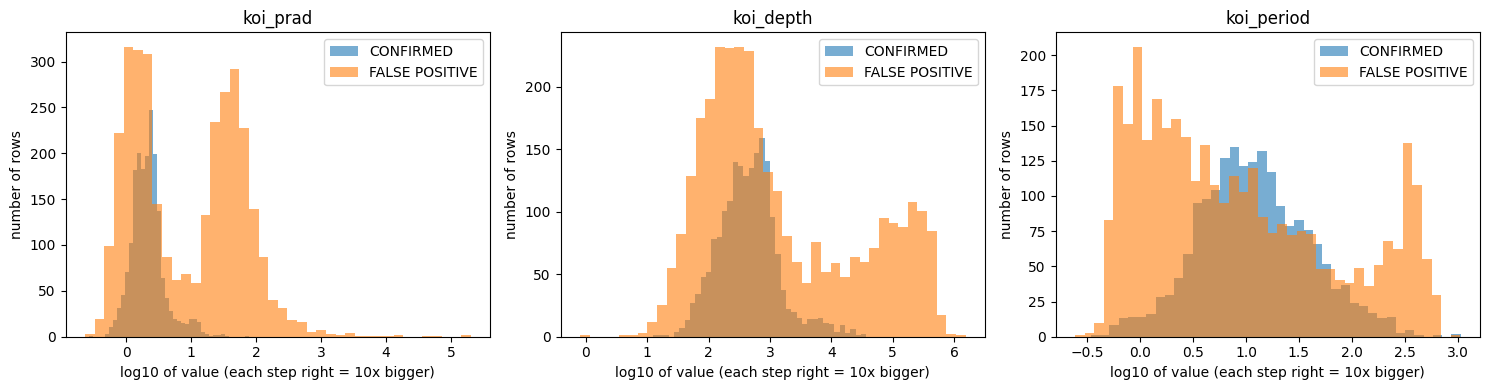

Constant columns: ['koi_eccen', 'koi_ldm_coeff4', 'koi_ldm_coeff3']
Input columns now: 33


In [30]:
# ===== 6. LOOK AT THE FINAL DATA (TRAINING PILE ONLY) =====
import matplotlib.pyplot as plt

# Stage 1: the first rows, and a summary of every input column
display(train_df[id_cols + [label_col] + feature_cols[:8]].head(10))
display(train_df[feature_cols].describe().T.round(2))

# Stage 2: planets vs false positives for three inputs
def plot_by_label(df, columns):
    """Draw one histogram per column, CONFIRMED and FALSE POSITIVE overlaid, on a log scale."""
    fig, axes = plt.subplots(1, len(columns), figsize=(5 * len(columns), 4))
    for ax, col in zip(axes, columns):
        for label, color in [("CONFIRMED", "tab:blue"), ("FALSE POSITIVE", "tab:orange")]:
            values = df.loc[df[label_col] == label, col].dropna()    # this label's values, gaps removed
            values = values[values > 0]                              # a log needs positive numbers
            ax.hist(np.log10(values), bins=40, alpha=0.6, color=color, label=label)
        ax.set_title(col)
        ax.set_xlabel("log10 of value (each step right = 10x bigger)")
        ax.set_ylabel("number of rows")
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_by_label(train_df, ["koi_prad", "koi_depth", "koi_period"])

# Stage 3: remove inputs that hold the same value in every training row
def find_constant_columns(df, columns):
    """Return the columns with at most one distinct value (blank cells are ignored)."""
    return [c for c in columns if df[c].nunique() <= 1]

constant_cols = find_constant_columns(train_df, feature_cols)
print("Constant columns:", constant_cols)       # expect ['koi_eccen', 'koi_ldm_coeff4', 'koi_ldm_coeff3']
feature_cols = [c for c in feature_cols if c not in constant_cols]
print("Input columns now:", len(feature_cols))  # expect 33

### FINAL FINISHING WORK BEGIN

In [31]:
# ===== CELL 1: train three models and compare them on the VALIDATION pile =====

# Stage 1: imports
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# Stage 2: split each pile into inputs (X) and answers (y); y = 1 means planet, 0 means false positive
def split_xy(df):
    """Return the model inputs X and the 0/1 answers y (1 = CONFIRMED planet) for one pile."""
    X = df[feature_cols]
    y = (df[label_col] == "CONFIRMED").astype(int)
    return X, y

X_train, y_train = split_xy(train_df)
X_val, y_val = split_xy(val_df)
X_test, y_test = split_xy(test_df)        # made now, but NOT used until Cell 2

# Stage 3: the three models we compare
models = {
    "Always says false positive": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(
        SimpleImputer(strategy="median"),                         # fill blanks with the middle value
        QuantileTransformer(output_distribution="normal", random_state=SEED),   # tame huge outliers
        LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=SEED),     # handles blanks by itself
}

# Stage 4: a function that scores a fitted model on one pile
def evaluate(model, X, y):
    """Return accuracy, precision, recall, F1 and AUC of a fitted model on one pile."""
    pred = model.predict(X)                       # hard answers: 0 or 1
    prob = model.predict_proba(X)[:, 1]           # how sure the model is that it is a planet
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "auc": roc_auc_score(y, prob),
    }

# Stage 5: train every model on the TRAIN pile, score it on the VALIDATION pile
val_rows = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    val_rows[name] = evaluate(model, X_val, y_val)
val_scores = pd.DataFrame(val_rows).T.round(3)
display(val_scores)

,accuracy,precision,recall,f1,auc
Always says false positive,0.637,0.000,0.000,0.000,0.500
Logistic regression,0.851,0.747,0.891,0.812,0.930
Gradient boosting,0.939,0.919,0.912,0.916,0.985


Chosen model: Gradient boosting

Top 8 inputs (bigger = the model needs it more):
koi_max_mult_ev     0.0293
koi_prad            0.0292
koi_dor             0.0215
koi_max_sngle_ev    0.0135
koi_ror             0.0106
koi_model_snr       0.0082
koi_smet            0.0053
ra                  0.0035
dtype: float64 

TEST scores: {'accuracy': 0.936, 'precision': 0.919, 'recall': 0.911, 'f1': 0.915, 'auc': 0.981}
Lazy model accuracy on test (the floor): 0.621


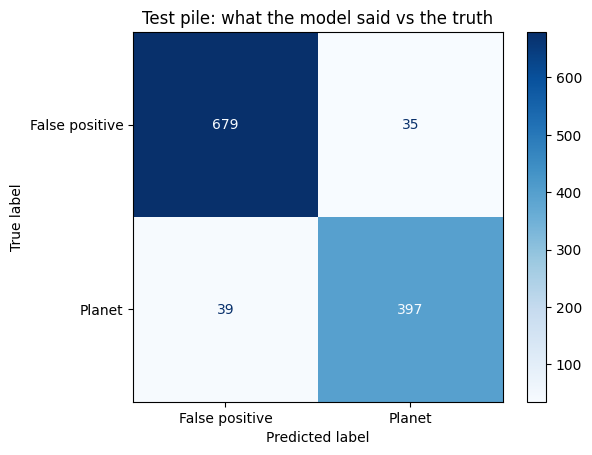

Planets caught: 397 of 436 | False alarms let through as planets: 35 of 714
Saved: results.json, planet_model.joblib, confusion_matrix.png


In [32]:
# ===== CELL 2: pick the winner, then the final exam on the TEST pile =====

# Stage 1: imports
import json, joblib
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Stage 2: pick the winner on VALIDATION (highest AUC among the two real models)
real_models = val_scores.drop(index="Always says false positive")
best_name = real_models["auc"].idxmax()
print("Chosen model:", best_name)

# Stage 3: which inputs does the chosen model lean on? (measured on VALIDATION, not test)
imp = permutation_importance(models[best_name], X_val, y_val,
                             scoring="roc_auc", n_repeats=5, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=feature_cols).sort_values(ascending=False)
print("\nTop 8 inputs (bigger = the model needs it more):")
print(importance.head(8).round(4), "\n")

# Stage 4: retrain a fresh copy of the winner on TRAIN + VALIDATION together
X_final = pd.concat([X_train, X_val])
y_final = pd.concat([y_train, y_val])
final_model = clone(models[best_name]).fit(X_final, y_final)

# Stage 5: score on the TEST pile, for the first and only time
test_scores = {k: round(float(v), 3) for k, v in evaluate(final_model, X_test, y_test).items()}
lazy_accuracy = round(float(1 - y_test.mean()), 3)    # accuracy of always answering "false positive"
print("TEST scores:", test_scores)
print("Lazy model accuracy on test (the floor):", lazy_accuracy)

# Stage 6: confusion matrix picture, saved as a file
test_pred = final_model.predict(X_test)
cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["False positive", "Planet"]).plot(cmap="Blues")
plt.title("Test pile: what the model said vs the truth")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Planets caught: {tp} of {tp + fn} | False alarms let through as planets: {fp} of {fp + tn}")

# Stage 7: save the results and the trained model
results = {
    "best_model": best_name,
    "validation": val_scores.to_dict(orient="index"),
    "test": test_scores,
    "test_lazy_accuracy": lazy_accuracy,
    "test_confusion_matrix": {"true_neg": int(tn), "false_pos": int(fp), "false_neg": int(fn), "true_pos": int(tp)},
    "top_features": importance.head(8).round(4).to_dict(),
    "n_features": len(feature_cols),
    "rows": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
}
with open("results.json", "w") as f:
    json.dump(results, f, indent=2)
joblib.dump({"model": final_model, "features": feature_cols}, "planet_model.joblib")
print("Saved: results.json, planet_model.joblib, confusion_matrix.png")

In [33]:
# ===== CELL 3: write the README automatically, with the real numbers filled in =====

def to_markdown_table(df):
    """Turn a small pandas table into a Markdown table string."""
    header = "| model | " + " | ".join(df.columns) + " |"
    divider = "|---|" + "---|" * len(df.columns)
    lines = [header, divider]
    for name, row in df.iterrows():
        lines.append(f"| {name} | " + " | ".join(str(v) for v in row.values) + " |")
    return "\n".join(lines)

top_feats = "\n".join(f"- `{k}`: {v}" for k, v in results["top_features"].items())
t, cmx, r = results["test"], results["test_confusion_matrix"], results["rows"]

readme = f"""# Planet or Not

A classifier that looks at NASA Kepler "objects of interest" and predicts whether each one is a **confirmed exoplanet** or a **false positive** (something that looked like a planet but was not).

**Scope, stated honestly:** this version uses only the summary numbers in NASA's KOI table. It does **not** use the light curves (the brightness-over-time data). A light-curve neural network was planned but is not part of this version.

## Data
- NASA Exoplanet Archive, Kepler Objects of Interest (cumulative table): 9,564 rows.
- Trained on rows labelled CONFIRMED or FALSE POSITIVE only ({r['train'] + r['val'] + r['test']:,} rows). CANDIDATE rows have no final answer, so they were set aside.

## Avoiding leakage (the main care taken)
- Removed columns that record how NASA decided the label: the disposition score, the Kepler pipeline's own verdict, the four false-positive test flags, vetting comments and dates, and the Kepler name (only given to confirmed planets). On the labelled rows, the pipeline verdict matched the label in 99.9% of cases, so keeping it would have made the task meaningless.
- Also set aside: empty columns, uncertainty columns, pipeline bookkeeping columns, and image-based centroid columns.
- Final model uses {results['n_features']} numeric inputs (orbit period, transit depth and duration, signal-to-noise, estimated object size, star properties and so on).

## Split
- Split **by star** (`kepid`), 70 / 15 / 15, fixed random seed. A star with several objects never appears in more than one pile.
- Rows: train {r['train']:,}, validation {r['val']:,}, test {r['test']:,}.
- The test pile was used once, after the model was chosen on validation.

## Results
Validation pile (used to choose the model):

{to_markdown_table(val_scores)}

Test pile, final model (**{results['best_model']}**, retrained on train + validation):

| accuracy | precision | recall | F1 | AUC |
|---|---|---|---|---|
| {t['accuracy']} | {t['precision']} | {t['recall']} | {t['f1']} | {t['auc']} |

- A model that always answers "false positive" gets **{results['test_lazy_accuracy']}** accuracy on the test pile, so that is the floor to beat.
- Confusion matrix on test: {cmx['true_pos']} planets caught, {cmx['false_neg']} planets missed, {cmx['false_pos']} false positives wrongly called planets, {cmx['true_neg']} false positives correctly rejected. See `confusion_matrix.png`.

Inputs the chosen model relied on most (permutation importance on the validation pile: how much AUC drops when an input is scrambled):
{top_feats}

## Limitations
- In the training-pile histograms, many false positives sit at very large sizes or very deep dips, where almost no planets are, so they are easy to spot. Harder look-alikes, which resemble small planets, are probably where most mistakes happen. This was not analysed separately.
- Only one train / validation / test split was used, so the scores have no error bars.
- No light curves were used, so the model cannot look at the actual shape of the dip.
- Not deployed: there is no web app yet. The saved model file can be loaded for that.
- Labels come from NASA's table, which includes decisions made by automated and human vetting, not independent ground truth.

## What I would do next
- Add light-curve features. A pre-folded Kepler dataset from the AstroNet project (Shallue & Vanderburg, 2018) is available and would avoid downloading raw files.
- Separate error analysis for the hard look-alikes.
- Repeat the split with several seeds to get error bars.

## Files
- `planet_model.joblib`: trained model and its list of input columns
- `results.json`: all scores
- `confusion_matrix.png`: test results picture
"""

with open("README.md", "w") as f:
    f.write(readme)
print(readme)

# Planet or Not

A classifier that looks at NASA Kepler "objects of interest" and predicts whether each one is a **confirmed exoplanet** or a **false positive** (something that looked like a planet but was not).

**Scope, stated honestly:** this version uses only the summary numbers in NASA's KOI table. It does **not** use the light curves (the brightness-over-time data). A light-curve neural network was planned but is not part of this version.

## Data
- NASA Exoplanet Archive, Kepler Objects of Interest (cumulative table): 9,564 rows.
- Trained on rows labelled CONFIRMED or FALSE POSITIVE only (7,587 rows). CANDIDATE rows have no final answer, so they were set aside.

## Avoiding leakage (the main care taken)
- Removed columns that record how NASA decided the label: the disposition score, the Kepler pipeline's own verdict, the four false-positive test flags, vetting comments and dates, and the Kepler name (only given to confirmed planets). On the labelled rows, the pipeline verdict m